# Explicabilidade v2: Car Parts (protocolo único v2)

**O que é explicado.** Para cada uma das 30 séries (sorteio SEED+1 sobre a amostra da base, regra do NB09), RF, GB e SVR são treinados na **última janela** (treino = série[:-H]), limpo ou com ruído σ=30% do desvio do próprio treino. SHAP e LIME explicam **os mesmos 30 pontos** desse modelo: as 29 linhas de treino mais recentes e o **ponto de previsão** (features do 1º passo da previsão, calculadas a partir do histórico que o modelo vê).

### Diferenças em relação ao NB09
| Item | NB09 | v2 |
|---|---|---|
| Pontos explicados | SHAP: todas as linhas de treino (árvores) ou 30 sorteadas (SVR); LIME: só a última linha de treino | os mesmos 30 pontos para SHAP e LIME |
| Features | 17, com lag_season = lag_12 duplicado | 15, sem duplicata; lag_12 é o lag sazonal |
| LIME | associação por substring (bug) | por índice (`as_map()[1]`) |
| SHAP do SVR | sem semente, nsamples=50, escala normalizada | semente fixa, nsamples = 2p + 2048, escala original |
| Agregação | média simples de importâncias em escala original | normalização por série (soma 1) antes da média |
| Ruído da estabilidade | gerador sequencial sobre as séries | semente por série, σ do próprio treino |
| Incerteza | nenhuma | IC de 95% por bootstrap sobre as séries (2000 reamostragens) |

Resultados oficiais: LIME com 200 amostras. Sensibilidade (1000 e 5000) e análise com lag_24 são **suplementares**.

In [1]:
import sys, json, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

_root = Path.cwd().resolve()
PROJECT_ROOT = next(c for c in (_root, *_root.parents) if (c / 'src' / 'pipeline_v2.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT))
from src import pipeline_v2 as pv

BASE = 'cp'
DIR = PROJECT_ROOT / 'results' / 'v2' / BASE / 'xai'
FN, FN24 = pv.feature_names(), pv.feature_names(com_lag24=True)
MOD = pv.MODELOS_XAI
MET = ['shap', 'lime']
pd.set_option('display.width', 250)

def ler(nome):
    p = DIR / f'xai_{BASE}_{nome}_pontos.csv'
    return pd.read_csv(p) if p.exists() else None

pts = {c: ler(c) for c in ['limpo', 'ruido30']}
sens = {(n, c): ler(f'{c}_lime{n}') for n in (1000, 5000) for c in ['limpo', 'ruido30']}
lag24 = {c: ler(f'{c}_lag24') for c in ['limpo', 'ruido30']}
for c, d in pts.items():
    print(c, d.groupby(['modelo', 'metodo']).serie.nunique().unstack().to_dict(), '| pontos por série:',
          d.groupby(['serie', 'modelo', 'metodo']).size().unique())

def imp_serie(d, nomes=FN, tipo=None):
    """Importância por série (média de |atribuição| nos pontos) normalizada para somar 1."""
    i = pv.importancia_por_serie(d, nomes, tipo)
    return pv.normalizar_por_serie(i, nomes)

imp = pd.concat([imp_serie(d) for d in pts.values()], ignore_index=True)
imp_prev = pd.concat([imp_serie(d, tipo='previsao') for d in pts.values()], ignore_index=True)

limpo {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [22]
ruido30 {'lime': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}, 'shap': {'GradientBoosting': 30, 'RandomForest': 30, 'SVR': 30}} | pontos por série: [22]


## 1. Importância global (normalizada por série) e top-10

In [2]:
def glob(i, modelo, metodo, cond, nomes=FN):
    return i[(i.modelo == modelo) & (i.metodo == metodo) & (i.condicao == cond)][nomes].mean()

linhas = []
for cond in ['limpo', 'ruido30']:
    for m in MOD:
        for met in MET:
            g = glob(imp, m, met, cond)
            linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                           'top10': ', '.join(g.sort_values(ascending=False).index[:10]),
                           'pos_lag_12': int(g.rank(ascending=False, method='min')['lag_12']),
                           'lag_1': g['lag_1'], 'roll_mean_3': g['roll_mean_3'], 'roll_mean_6': g['roll_mean_6'],
                           'lag_12': g['lag_12']})
top = pd.DataFrame(linhas)
top.to_csv(DIR / f'xai_{BASE}_top10_global.csv', index=False)
for cond in ['limpo', 'ruido30']:
    print(f'=== {cond} ===')
    for _, r in top[top.condicao == cond].iterrows():
        print(f"{r.modelo:<17} {r.metodo:<5} lag_12 em {r.pos_lag_12:>2}º | {r.top10}")
    print()

=== limpo ===
RandomForest      shap  lag_12 em  9º | roll_mean_6, lag_6, lag_1, roll_std_3, roll_mean_3, lag_3, lag_7, lag_9, lag_12, lag_2
RandomForest      lime  lag_12 em  9º | roll_mean_6, lag_1, lag_6, lag_3, roll_std_3, lag_7, roll_mean_3, lag_2, lag_12, lag_9
GradientBoosting  shap  lag_12 em  8º | roll_mean_6, lag_6, lag_3, lag_7, lag_9, lag_1, lag_8, lag_12, lag_10, roll_mean_3
GradientBoosting  lime  lag_12 em  7º | lag_3, lag_6, lag_1, roll_mean_6, lag_9, lag_7, lag_12, lag_10, lag_8, lag_4
SVR               shap  lag_12 em  8º | lag_1, lag_2, roll_std_3, lag_4, lag_6, lag_3, roll_mean_6, lag_12, lag_7, lag_9
SVR               lime  lag_12 em  8º | lag_1, lag_2, lag_3, lag_4, lag_6, lag_9, lag_7, lag_12, lag_8, lag_5

=== ruido30 ===
RandomForest      shap  lag_12 em 13º | lag_10, lag_6, lag_9, roll_mean_6, lag_1, lag_7, lag_8, roll_std_3, lag_2, lag_3
RandomForest      lime  lag_12 em 12º | lag_10, lag_6, lag_9, roll_mean_6, lag_7, lag_1, roll_std_3, lag_8, lag_2, lag_3
Gr

## 2. Estabilidade entre limpo e ruído σ=30% (por série), com IC por bootstrap
Spearman entre os vetores de importância da mesma série (limpo x ruído) e Jaccard dos conjuntos top-3 e top-5. Estatística: média entre as 30 séries; IC 95% por bootstrap (2000). A mediana também é reportada.

In [3]:
def tab_estab(i, nomes=FN):
    linhas = []
    for met in MET:
        sub = i[i.metodo == met]
        e = pv.estabilidade(sub[sub.condicao == 'limpo'], sub[sub.condicao == 'ruido30'], nomes)
        for m in MOD:
            em = e[e.modelo == m]
            lin = {'modelo': m, 'metodo': met, 'n_series': len(em)}
            for col in ['spearman', 'jaccard_top3', 'jaccard_top5']:
                est, lo, hi = pv.bootstrap_ic(em[col].values)
                lin[col] = f'{est:.3f} [{lo:.3f}; {hi:.3f}]'
                lin[f'{col}_mediana'] = round(float(em[col].median()), 3)
            linhas.append(lin)
    return pd.DataFrame(linhas)

estab = tab_estab(imp)
estab.to_csv(DIR / f'xai_{BASE}_estabilidade.csv', index=False)
print(estab.to_string(index=False))

          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.173 [0.061; 0.271]             0.220 0.250 [0.173; 0.333]                   0.2 0.302 [0.235; 0.366]                 0.250
GradientBoosting   shap        30 0.204 [0.104; 0.296]             0.227 0.237 [0.160; 0.323]                   0.2 0.319 [0.252; 0.387]                 0.250
             SVR   shap        29 0.469 [0.377; 0.558]             0.525 0.376 [0.286; 0.476]                   0.2 0.459 [0.394; 0.524]                 0.429
    RandomForest   lime        30 0.166 [0.053; 0.282]             0.152 0.257 [0.183; 0.337]                   0.2 0.302 [0.236; 0.368]                 0.250
GradientBoosting   lime        30 0.199 [0.106; 0.287]             0.245 0.220 [0.153; 0.287]                   0.2 0.322 [0.266; 0.376]                 0.250
             SVR   lime        30 0.326 [0.236

## 3. Concordância SHAP x LIME
(a) Entre as importâncias globais (normalizadas por série): Pearson (normalização pelo máximo, como na Fig. 20) e Spearman. (b) Por série: Spearman entre o vetor SHAP e o vetor LIME da mesma série, média com IC.

In [4]:
def tab_conc(i, nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            s, l = glob(i, m, 'shap', cond, nomes), glob(i, m, 'lime', cond, nomes)
            pear = np.corrcoef((s / s.max()).values, (l / l.max()).values)[0, 1]
            spe = spearmanr(s.values, l.values)[0]
            a = i[(i.modelo == m) & (i.condicao == cond)]
            j = a[a.metodo == 'shap'].merge(a[a.metodo == 'lime'], on='serie', suffixes=('_s', '_l'))
            por_serie = [spearmanr(r[[f'{n}_s' for n in nomes]].astype(float), r[[f'{n}_l' for n in nomes]].astype(float))[0]
                         for _, r in j.iterrows()]
            est, lo, hi = pv.bootstrap_ic(por_serie)
            linhas.append({'condicao': cond, 'modelo': m, 'pearson_global': round(pear, 3), 'spearman_global': round(spe, 3),
                           'spearman_por_serie': f'{est:.3f} [{lo:.3f}; {hi:.3f}]'})
    return pd.DataFrame(linhas)

conc = tab_conc(imp)
conc.to_csv(DIR / f'xai_{BASE}_concordancia_shap_lime.csv', index=False)
print(conc.to_string(index=False))

condicao           modelo  pearson_global  spearman_global   spearman_por_serie
   limpo     RandomForest           0.911            0.964 0.842 [0.783; 0.890]
   limpo GradientBoosting           0.708            0.854 0.792 [0.737; 0.843]
   limpo              SVR           0.791            0.654 0.658 [0.530; 0.764]
 ruido30     RandomForest           0.977            0.961 0.807 [0.735; 0.859]
 ruido30 GradientBoosting           0.948            0.907 0.739 [0.683; 0.795]
 ruido30              SVR           0.914            0.729 0.836 [0.788; 0.875]


## 4. Posição do lag_12 (lag sazonal): global e por série

In [5]:
def pos_lag(i, feat='lag_12', nomes=FN):
    linhas = []
    for cond in ['limpo', 'ruido30']:
        for m in MOD:
            for met in MET:
                sub = i[(i.modelo == m) & (i.metodo == met) & (i.condicao == cond)]
                r = sub[nomes].rank(axis=1, ascending=False, method='min')[feat]
                g = glob(i, m, met, cond, nomes)
                linhas.append({'condicao': cond, 'modelo': m, 'metodo': met,
                               'pos_global': int(g.rank(ascending=False, method='min')[feat]),
                               'pos_mediana_por_serie': float(r.median()),
                               '% séries no top-3': round(100 * (r <= 3).mean(), 1),
                               'importância normalizada': round(g[feat], 4)})
    return pd.DataFrame(linhas)

lag12 = pos_lag(imp)
lag12.to_csv(DIR / f'xai_{BASE}_posicao_lag12.csv', index=False)
print(lag12.to_string(index=False))

condicao           modelo metodo  pos_global  pos_mediana_por_serie  % séries no top-3  importância normalizada
   limpo     RandomForest   shap           9                    7.5               16.7                   0.0553
   limpo     RandomForest   lime           9                    9.0               20.0                   0.0579
   limpo GradientBoosting   shap           8                    7.5               13.3                   0.0617
   limpo GradientBoosting   lime           7                    7.0               23.3                   0.0636
   limpo              SVR   shap           8                    9.0               16.7                   0.0659
   limpo              SVR   lime           8                    9.0               16.7                   0.0622
 ruido30     RandomForest   shap          13                    9.0               13.3                   0.0535
 ruido30     RandomForest   lime          12                    9.0               10.0                  

## 5. Redistribuição de importância sob ruído (equivalente à Fig. 22)
Importância normalizada (fração da soma por série) de lag_1, roll_mean_3 e roll_mean_6, limpo x ruído, com IC 95% por bootstrap sobre as séries.

          modelo metodo     feature  limpo       limpo_ic  ruido30     ruido30_ic       Δ (ruído − limpo)  IC inclui zero
    RandomForest   shap       lag_1  0.095 [0.051; 0.145]    0.072 [0.051; 0.098] -0.023 [-0.072; +0.025]            True
    RandomForest   shap roll_mean_3  0.072 [0.046; 0.102]    0.050 [0.030; 0.075] -0.023 [-0.055; +0.010]            True
    RandomForest   shap roll_mean_6  0.174 [0.112; 0.244]    0.073 [0.047; 0.103] -0.100 [-0.170; -0.041]           False
    RandomForest   shap      lag_12  0.055 [0.025; 0.100]    0.053 [0.036; 0.075] -0.002 [-0.051; +0.037]            True
    RandomForest   lime       lag_1  0.111 [0.064; 0.165]    0.070 [0.056; 0.087] -0.041 [-0.094; +0.007]            True
    RandomForest   lime roll_mean_3  0.061 [0.041; 0.085]    0.049 [0.039; 0.060] -0.013 [-0.037; +0.010]            True
    RandomForest   lime roll_mean_6  0.123 [0.080; 0.172]    0.072 [0.054; 0.093] -0.051 [-0.095; -0.012]           False
    RandomForest   lime 

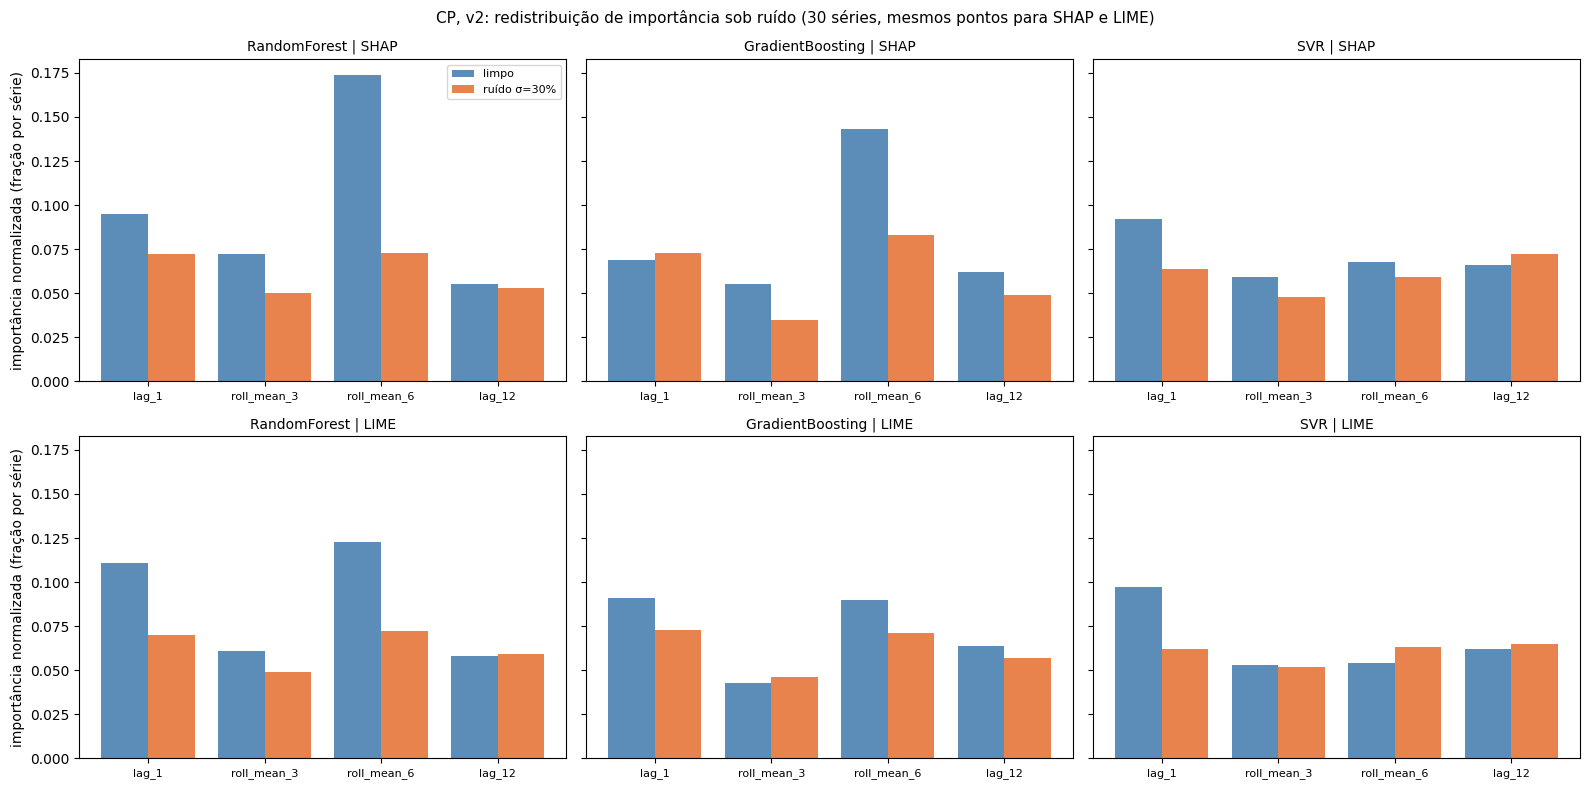

In [6]:
FEATS = ['lag_1', 'roll_mean_3', 'roll_mean_6', 'lag_12']
linhas = []
for m in MOD:
    for met in MET:
        for f in FEATS:
            lin = {'modelo': m, 'metodo': met, 'feature': f}
            for cond in ['limpo', 'ruido30']:
                v = imp[(imp.modelo == m) & (imp.metodo == met) & (imp.condicao == cond)][f].values
                est, lo, hi = pv.bootstrap_ic(v)
                lin[cond], lin[f'{cond}_ic'] = round(est, 3), f'[{lo:.3f}; {hi:.3f}]'
            a = imp[(imp.modelo == m) & (imp.metodo == met)]
            j = a[a.condicao == 'limpo'][['serie', f]].merge(a[a.condicao == 'ruido30'][['serie', f]], on='serie')
            est, lo, hi = pv.bootstrap_ic((j[f'{f}_y'] - j[f'{f}_x']).values)
            lin['Δ (ruído − limpo)'] = f'{est:+.3f} [{lo:+.3f}; {hi:+.3f}]'
            lin['IC inclui zero'] = lo <= 0 <= hi
            linhas.append(lin)
redis = pd.DataFrame(linhas)
redis.to_csv(DIR / f'xai_{BASE}_redistribuicao_ruido.csv', index=False)
print(redis.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
for r_, met in enumerate(MET):
    for c_, m in enumerate(MOD):
        ax = axes[r_, c_]; sub = redis[(redis.modelo == m) & (redis.metodo == met)]
        x = np.arange(len(FEATS))
        ax.bar(x - 0.2, sub['limpo'], 0.4, label='limpo', color='#5B8DB8')
        ax.bar(x + 0.2, sub['ruido30'], 0.4, label='ruído σ=30%', color='#E8834E')
        ax.set_xticks(x); ax.set_xticklabels(FEATS, fontsize=8); ax.set_title(f'{m} | {met.upper()}', fontsize=10)
        if c_ == 0: ax.set_ylabel('importância normalizada (fração por série)')
axes[0, 0].legend(fontsize=8)
fig.suptitle(f'{BASE.upper()}, v2: redistribuição de importância sob ruído (30 séries, mesmos pontos para SHAP e LIME)', fontsize=11)
plt.tight_layout(); plt.savefig(DIR / f'fig_v2_{BASE}_redistribuicao_ruido.png', dpi=150, bbox_inches='tight'); plt.show()

### 5.1 Só o ponto de previsão (suplementar)
As mesmas métricas usando apenas o ponto de previsão (1 ponto por série), em vez dos 30 pontos.

In [7]:
print('Estabilidade (só o ponto de previsão):'); print(tab_estab(imp_prev).to_string(index=False)); print()
print('Concordância SHAP x LIME (só o ponto de previsão):'); print(tab_conc(imp_prev).to_string(index=False))

Estabilidade (só o ponto de previsão):
          modelo metodo  n_series             spearman  spearman_mediana         jaccard_top3  jaccard_top3_mediana         jaccard_top5  jaccard_top5_mediana
    RandomForest   shap        30 0.118 [0.017; 0.210]             0.178 0.247 [0.167; 0.333]                   0.2 0.271 [0.219; 0.320]                 0.250
GradientBoosting   shap        30 0.110 [0.003; 0.201]             0.172 0.217 [0.157; 0.280]                   0.2 0.281 [0.225; 0.338]                 0.250
             SVR   shap        29 0.398 [0.289; 0.505]             0.370 0.376 [0.293; 0.466]                   0.5 0.454 [0.385; 0.532]                 0.429
    RandomForest   lime        30 0.119 [0.012; 0.223]             0.177 0.223 [0.150; 0.293]                   0.2 0.266 [0.206; 0.322]                 0.250
GradientBoosting   lime        30 0.099 [0.000; 0.187]             0.093 0.197 [0.120; 0.287]                   0.2 0.268 [0.207; 0.328]                 0.250
       

## 6. Sensibilidade do LIME (1000 e 5000 amostras), separada do resultado oficial
O SHAP é o mesmo do resultado oficial; só o LIME muda.

In [8]:
linhas = []
for n in (200, 1000, 5000):
    if n == 200:
        lime_d = {c: pts[c][pts[c].metodo == 'lime'] for c in pts}
    else:
        if any(sens[(n, c)] is None for c in pts):
            print(f'sem cache para {n} amostras'); continue
        lime_d = {c: sens[(n, c)] for c in pts}
    comb = pd.concat([imp_serie(pts[c][pts[c].metodo == 'shap']) for c in pts] +
                     [imp_serie(lime_d[c]) for c in pts], ignore_index=True)
    cc = tab_conc(comb); pl = pos_lag(comb); es = tab_estab(comb)
    for m in MOD:
        for cond in ['limpo', 'ruido30']:
            g = glob(comb, m, 'lime', cond)
            linhas.append({'lime_samples': n, 'modelo': m, 'condicao': cond,
                           'pearson_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].pearson_global.iloc[0],
                           'spearman_shap_lime': cc[(cc.modelo == m) & (cc.condicao == cond)].spearman_global.iloc[0],
                           'pos_lag_12_lime': pl[(pl.modelo == m) & (pl.condicao == cond) & (pl.metodo == 'lime')].pos_global.iloc[0],
                           'estab_spearman_lime': es[(es.modelo == m) & (es.metodo == 'lime')].spearman.iloc[0] if cond == 'limpo' else '',
                           'top10_lime': ', '.join(g.sort_values(ascending=False).index[:10])})
sens_tab = pd.DataFrame(linhas)
sens_tab.to_csv(DIR / f'xai_{BASE}_sensibilidade_lime.csv', index=False)
print(sens_tab.drop(columns='top10_lime').to_string(index=False)); print()
for _, r in sens_tab[sens_tab.condicao == 'limpo'].iterrows():
    print(f'{r.lime_samples:>5} {r.modelo:<17} {r.top10_lime}')

sem cache para 1000 amostras
sem cache para 5000 amostras
 lime_samples           modelo condicao  pearson_shap_lime  spearman_shap_lime  pos_lag_12_lime  estab_spearman_lime
          200     RandomForest    limpo              0.911               0.964                9 0.166 [0.053; 0.282]
          200     RandomForest  ruido30              0.977               0.961               12                     
          200 GradientBoosting    limpo              0.708               0.854                7 0.199 [0.106; 0.287]
          200 GradientBoosting  ruido30              0.948               0.907               12                     
          200              SVR    limpo              0.791               0.654                8 0.326 [0.236; 0.420]
          200              SVR  ruido30              0.914               0.729               12                     

  200 RandomForest      roll_mean_6, lag_1, lag_6, lag_3, roll_std_3, lag_7, roll_mean_3, lag_2, lag_12, lag_9
  200 Gradi

## 7. Análise SUPLEMENTAR (não oficial): última janela com lag_24 incluído
16 features (as 15 oficiais + lag_24). Os números não substituem os oficiais.

In [9]:
if all(lag24[c] is not None for c in lag24):
    imp24 = pd.concat([imp_serie(lag24[c], FN24) for c in lag24], ignore_index=True)
    p12, p24 = pos_lag(imp24, 'lag_12', FN24), pos_lag(imp24, 'lag_24', FN24)
    sup = p12[['condicao', 'modelo', 'metodo', 'pos_global', '% séries no top-3']].rename(
        columns={'pos_global': 'pos lag_12', '% séries no top-3': 'lag_12 top-3 (%)'})
    sup['pos lag_24'] = p24['pos_global'].values
    sup['lag_24 top-3 (%)'] = p24['% séries no top-3'].values
    sup['lag_12 + lag_24 (fração)'] = (p12['importância normalizada'] + p24['importância normalizada']).round(3).values
    print(sup.to_string(index=False))
    print('\nConcordância SHAP x LIME com lag_24:'); print(tab_conc(imp24, FN24).to_string(index=False))
    print('\nEstabilidade com lag_24:'); print(tab_estab(imp24, FN24).to_string(index=False))
    sup.to_csv(DIR / f'xai_{BASE}_suplementar_lag24.csv', index=False)
else:
    print('caches com lag_24 ausentes')

caches com lag_24 ausentes
